# My details :
*   Name : Tushar Kaldate
*   Roll : 47
*   Batch : A2
* PRN : 202401040191

# GitHub Repo : https://github.com/tusharkkp/AI-ML-Lab-Practicals/

# PRACTICAL NO. 03 —  Regression Model
## [1] Title
**Performance Evaluation of Regression Models — Real-World Application: Air Quality (CO concentration prediction)**

## [2] Aim
To develop, train and compare regression models — **Simple Linear, Multiple Linear, Polynomial (degree 2), Locally Weighted Linear Regression (LWLR), Gradient-Descent Linear Regression, and Ridge / Lasso / Elastic Net** — on the real-world *Air Quality* dataset (hourly readings of a gas-multisensor device in an Italian city), and to evaluate them with **MSE, RMSE and R²**.

The continuous target variable is **CO(GT)** – the true hourly averaged carbon-monoxide concentration (mg/m³), measured by a reference analyser. The models predict it from the cheap metal-oxide sensors (PT08.S1–S5), temperature, relative/absolute humidity and time-of-day information. A good model therefore acts as a **low-cost virtual (soft) sensor** for CO.

## [3] Exp Objectives
1. **Data preparation** – select a dataset with a continuous target, treat missing values (encoded as `-200`), and encode categorical features.
2. **Model design** – implement Simple, Multiple and Polynomial regression (plus LWLR, Gradient Descent, Ridge, Lasso and Elastic Net).
3. **Training & evaluation** – split into train/test sets, train every model on the training set, and evaluate with MSE, RMSE and R².
4. **Comparative analysis** – compare strengths, weaknesses, interpretability, computational efficiency and model complexity.
5. **Gradient Descent** – implement GD for linear regression from scratch and analyse the effect of the learning rate, convergence and batch size.
6. **Conclusion** – summarise findings, give recommendations and discuss improvements.

## [4] Exp Outcome
After completing this experiment the student will be able to:
- Pre-process a real, noisy sensor dataset (sentinel missing values, empty columns, date-time features, one-hot encoding, scaling).
- Build and explain simple, multiple, polynomial, locally-weighted and regularised regression models.
- Implement batch, mini-batch and stochastic **gradient descent** from scratch and verify it against the closed-form (Normal-equation) solution.
- Choose and interpret regression metrics (**MSE, RMSE, R²**) and diagnose under-/over-fitting from train-vs-test results.
- Select a suitable model for a real application by trading off accuracy, interpretability and computational cost.

## [5] Conceptual Details

**Regression** predicts a continuous target $y$ from features $\mathbf{x}$.

| Model | Hypothesis / idea | Key points |
|---|---|---|
| **Simple Linear** | $\hat y=\theta_0+\theta_1x$ | One feature; most interpretable; high bias |
| **Multiple (Multivariate) Linear** | $\hat y=\theta_0+\sum_j\theta_jx_j=\mathbf{\theta}^T\mathbf{x}$ | Closed form: $\theta=(X^TX)^{-1}X^Ty$ (Normal equation); sensitive to multicollinearity |
| **Polynomial (degree 2)** | $\hat y=\theta_0+\sum\theta_jx_j+\sum\theta_{jk}x_jx_k$ | Still *linear in parameters*; captures curvature & interactions; feature count grows $O(d^2)$ → over-fitting risk |
| **LWLR** | For each query $x$, fit weighted least squares with weights $w^{(i)}=\exp\!\big(-\|x^{(i)}-x\|^2/2\tau^2\big)$ | Non-parametric, local fit; bandwidth $\tau$ controls bias–variance; **no training but slow prediction** |
| **Gradient Descent** | $\theta:=\theta-\alpha\,\frac{1}{m}X^T(X\theta-y)$ | Iterative optimiser; scales to huge data; needs feature scaling and a good learning rate $\alpha$ |
| **Ridge (L2)** | minimise $\text{MSE}+\alpha\sum\theta_j^2$ | Shrinks coefficients, handles multicollinearity |
| **Lasso (L1)** | minimise $\text{MSE}+\alpha\sum|\theta_j|$ | Shrinks and can set coefficients to exactly 0 → feature selection |
| **Elastic Net** | minimise $\text{MSE}+\alpha\big[\rho\sum|\theta_j|+\tfrac{1-\rho}{2}\sum\theta_j^2\big]$ | Mix of L1 and L2; good with correlated features |

**Cost function:** $J(\theta)=\dfrac{1}{2m}\sum_{i=1}^{m}\big(\hat y^{(i)}-y^{(i)}\big)^2$

**Evaluation metrics**
- **MSE** $=\frac1n\sum(y_i-\hat y_i)^2$ – penalises large errors.
- **RMSE** $=\sqrt{\text{MSE}}$ – same unit as the target (mg/m³ here).
- **R²** $=1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ – proportion of variance explained (1 = perfect, 0 = as good as predicting the mean).

## [6] Algorithm / Flowchart

```
                    ┌──────────────────────────────┐
                    │  Load Air Quality.csv        │
                    └──────────────┬───────────────┘
                                   ▼
                    ┌──────────────────────────────┐
                    │ Replace -200 with NaN, drop  │
                    │ empty rows/cols (NMHC ~90%)  │
                    └──────────────┬───────────────┘
                                   ▼
                    ┌──────────────────────────────┐
                    │ Feature engineering: Hour →  │
                    │ TimeOfDay, Weekend; one-hot  │
                    │ encode categorical features  │
                    └──────────────┬───────────────┘
                                   ▼
                    ┌──────────────────────────────┐
                    │ Train / Test split (80 / 20) │
                    └──────────────┬───────────────┘
                                   ▼
                    ┌──────────────────────────────┐
                    │ Median imputation + Standard │
                    │ scaling (fit on TRAIN only)  │
                    └──────────────┬───────────────┘
                                   ▼
   ┌────────┬────────┬────────┬────┴───┬────────┬─────────────┐
   ▼        ▼        ▼        ▼        ▼        ▼             ▼
 Simple  Multiple  Poly-2    LWLR   Gradient  Ridge /      (tune α, τ,
 Linear  Linear   (deg 2)           Descent   Lasso /      lr via CV /
                                              ElasticNet    validation)
   └────────┴────────┴────────┬───────┴────────┴─────────────┘
                              ▼
                ┌──────────────────────────────┐
                │ Predict on TEST → MSE, RMSE, │
                │ R², fit time, #parameters    │
                └──────────────┬───────────────┘
                               ▼
                ┌──────────────────────────────┐
                │ Compare models → conclusion  │
                └──────────────────────────────┘
```

**Algorithm (gradient descent for linear regression)**
1. Standardise features, add a bias column of ones, initialise $\theta=\mathbf 0$.
2. Repeat for a fixed number of epochs: compute predictions $\hat y=X\theta$; gradient $\nabla J=\frac1m X^T(\hat y-y)$; update $\theta\leftarrow\theta-\alpha\nabla J$; record $J(\theta)$.
3. Stop when $J$ stops decreasing; compare $\theta$ with the Normal-equation solution.

**Algorithm (LWLR)** – for every test point $x$: compute weights $w^{(i)}$ → solve $\theta_x=(X^TWX)^{-1}X^TWy$ → predict $\hat y=x^T\theta_x$.

**Simple Linear Regression**

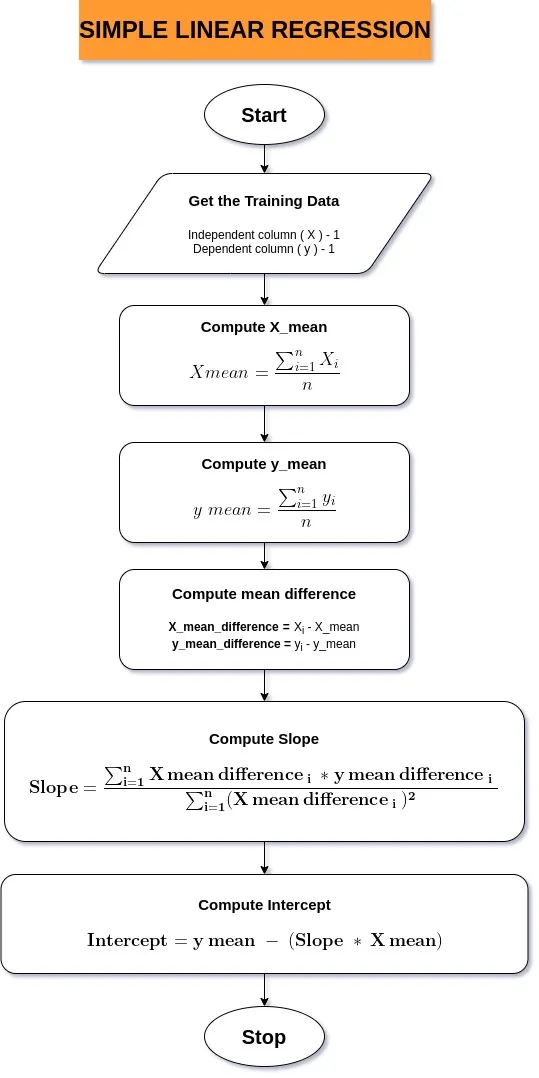

**Multiple Linear Regression**

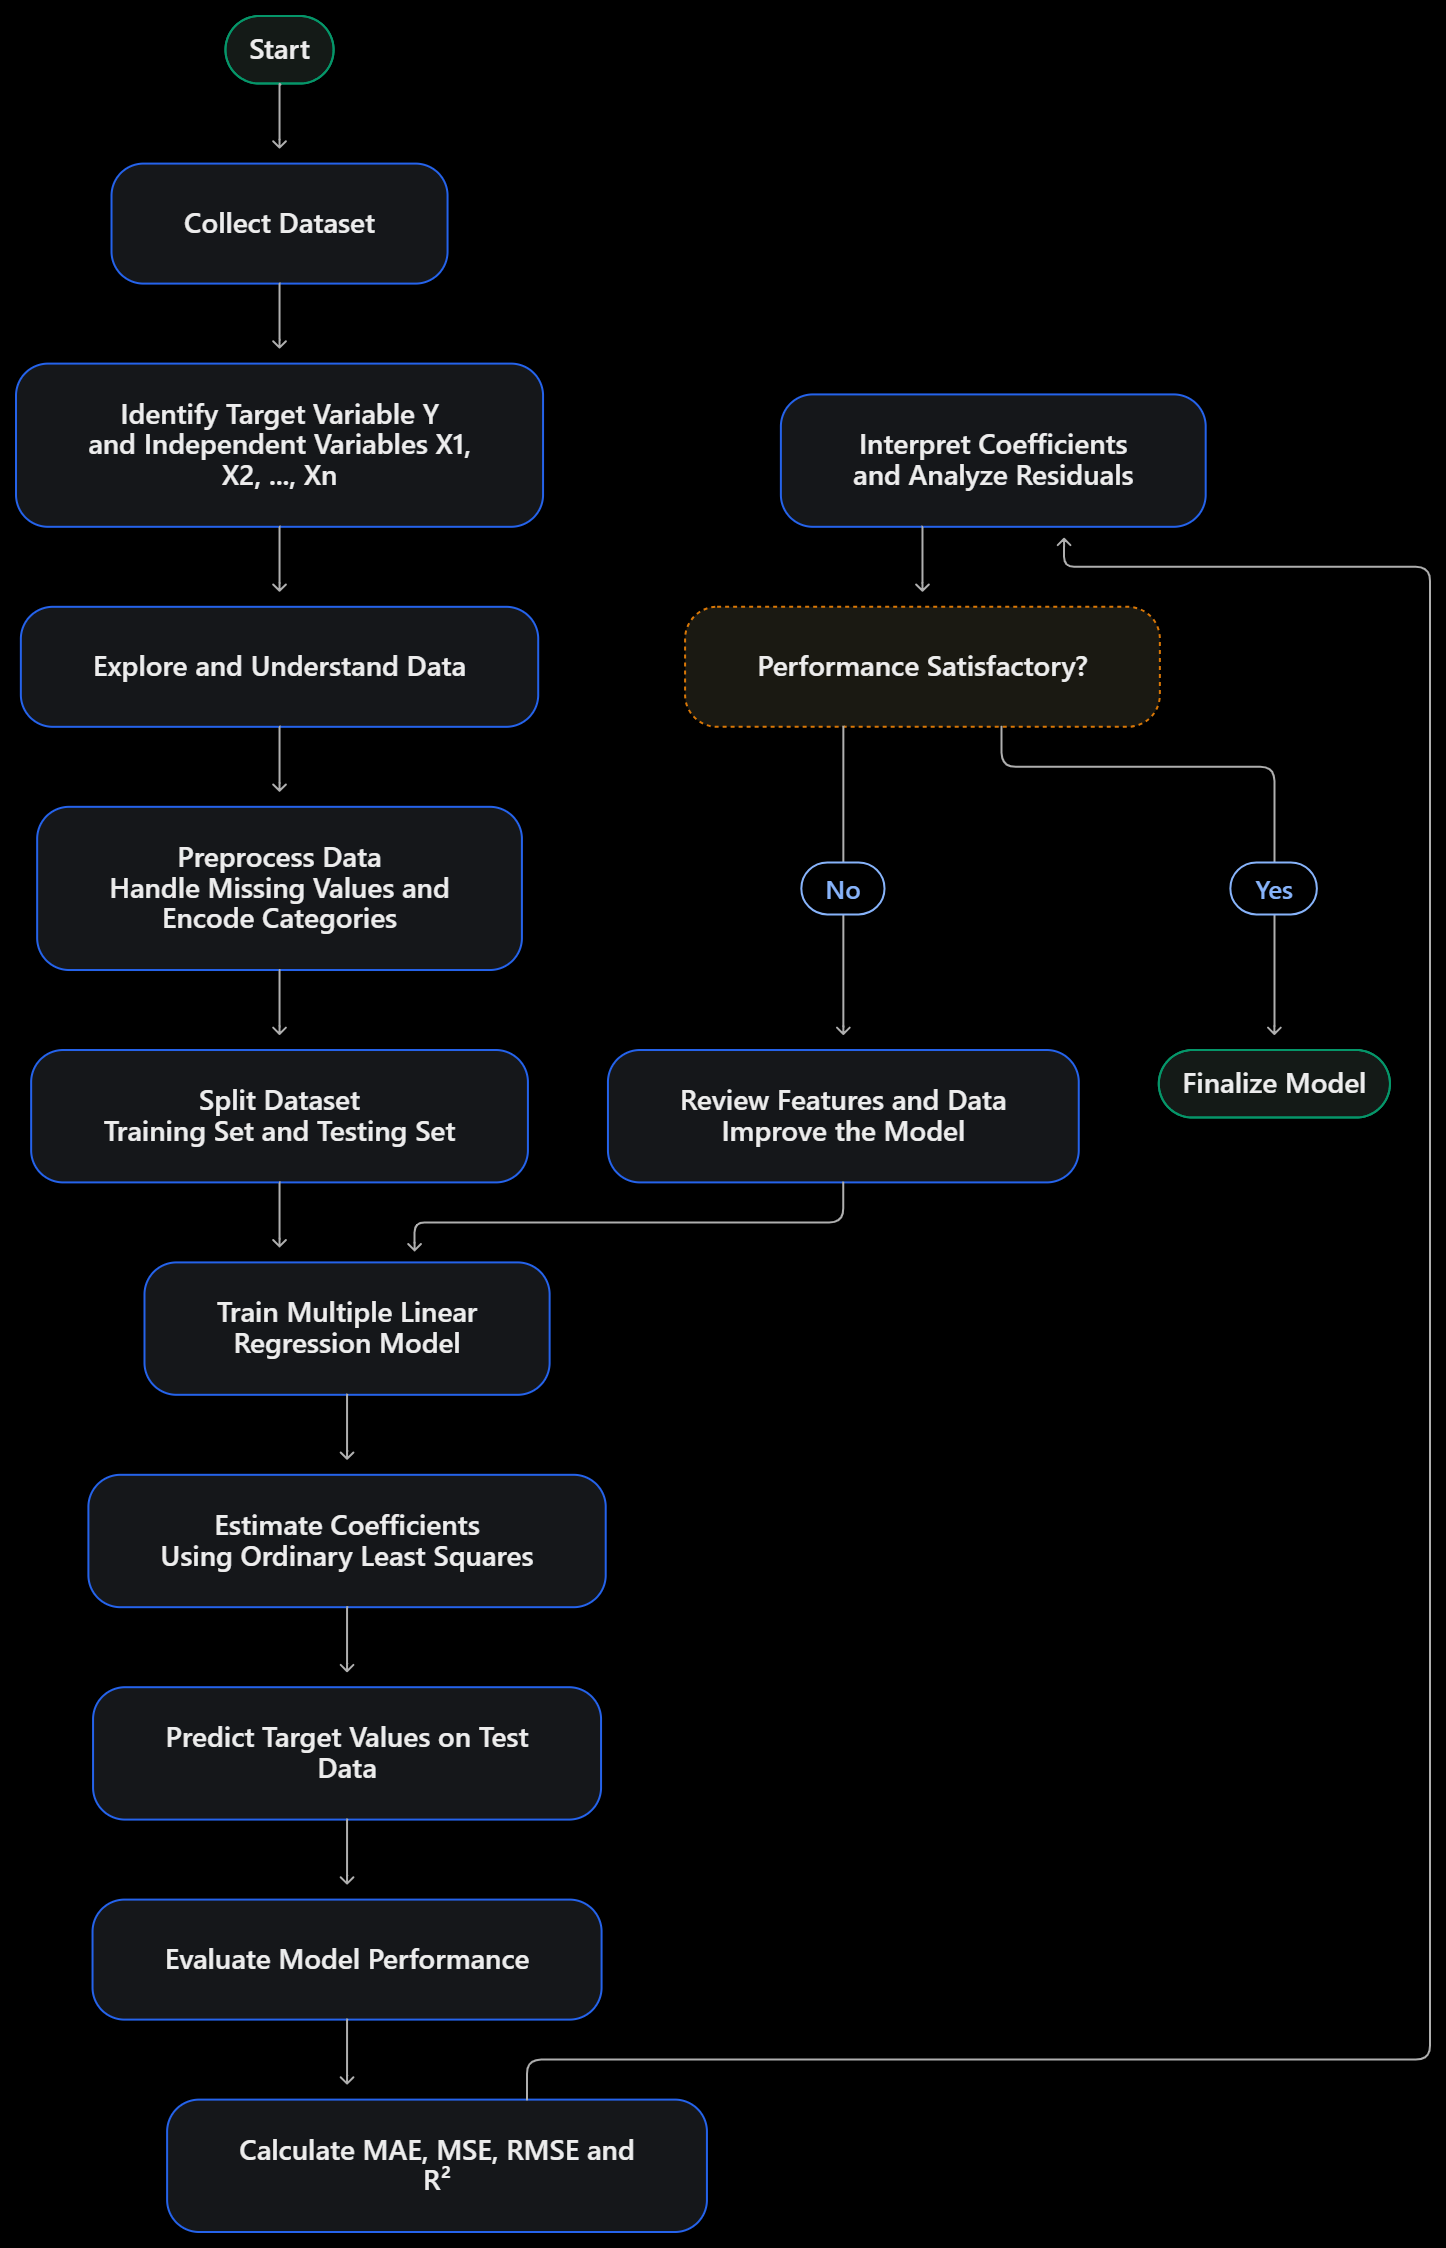

**Polynomial Regression (degree 2)**

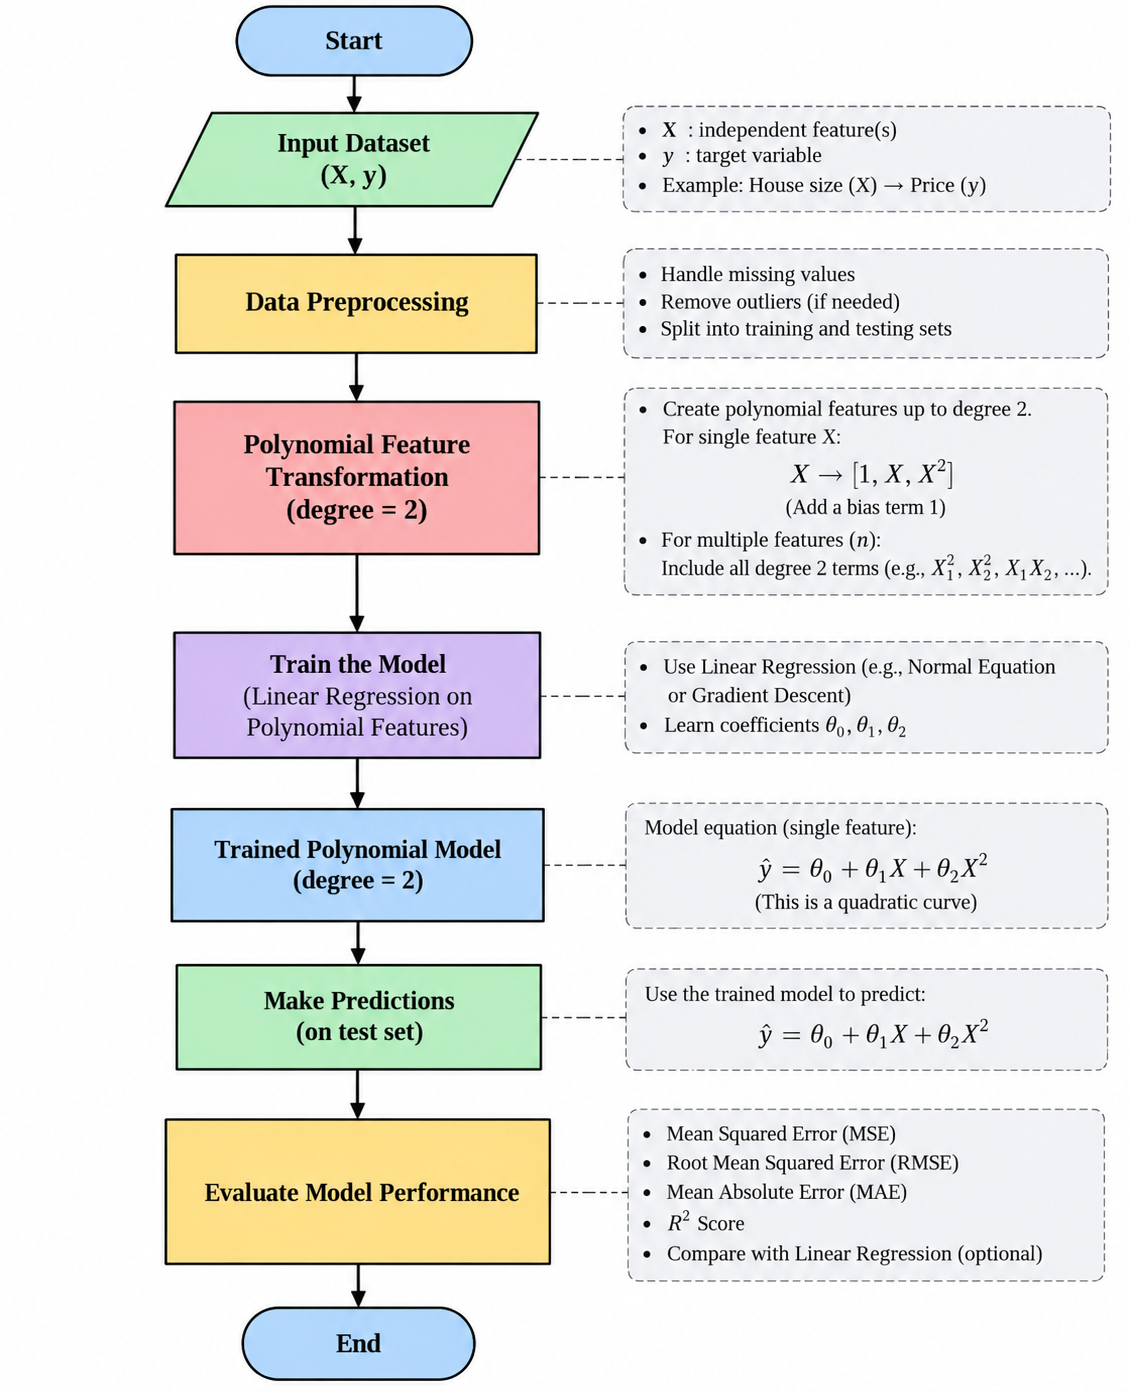

**Locally Weighted Linear Regression (LWLR)**

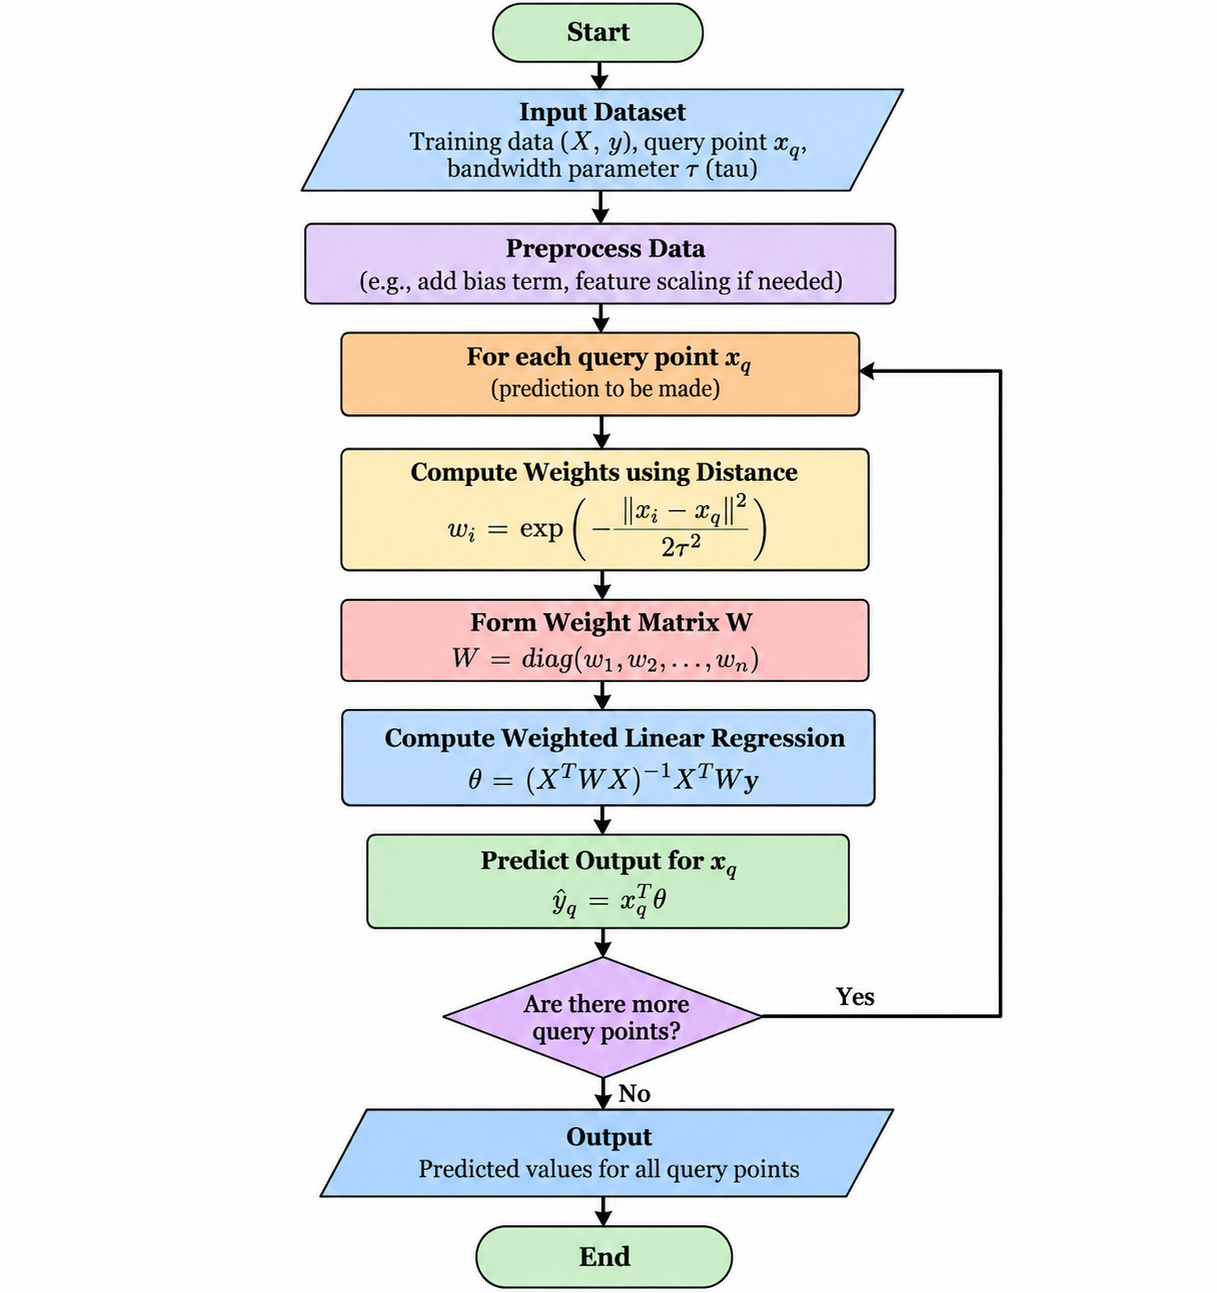

**Gradient Descent for linear regression**

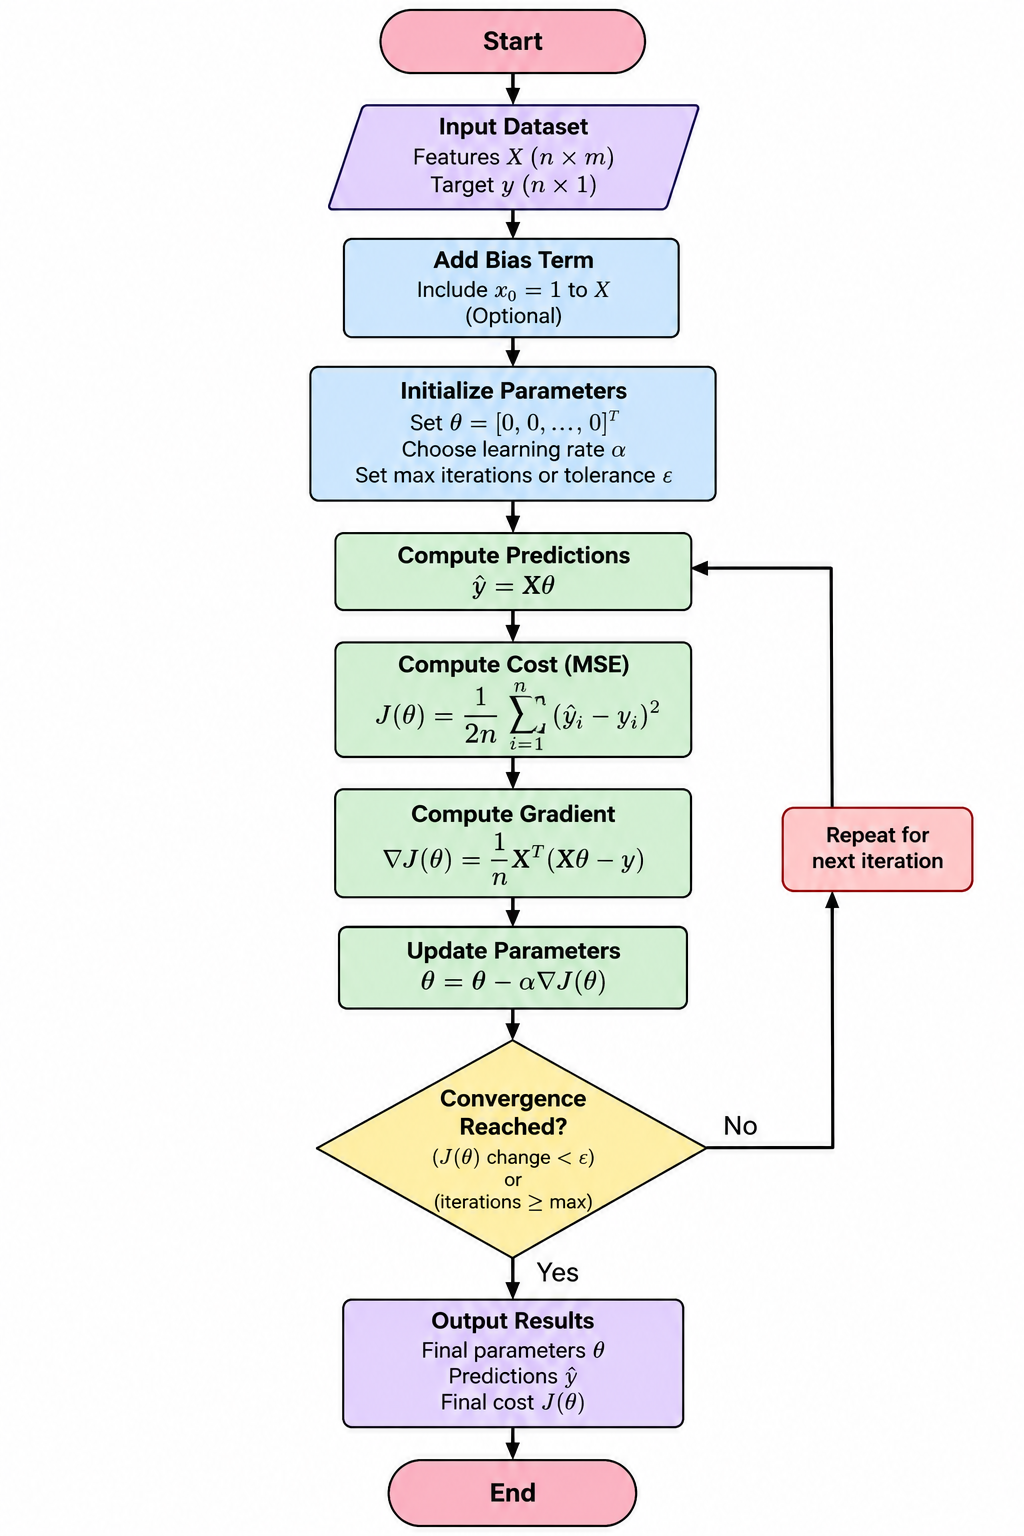

## [7] Python Code

---
# 1. Data Preparation

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded.")

Libraries loaded.


### 1.1 Load the dataset
The dataset (UCI *Air Quality*, 9 358 hourly instances, March 2004 – April 2005) contains responses of 5 metal-oxide chemical sensors together with ground-truth (GT) concentrations from a reference analyser. Missing values are tagged with **-200**.

In [ ]:
# Works locally and on Colab (upload the CSV next to the notebook)
for path in ["Air Quality.csv", "Air_Quality.csv", "/mnt/user-data/uploads/Air_Quality.csv"]:
    if os.path.exists(path):
        break
df_raw = pd.read_csv(path)
print("Loaded from:", path)
print("Shape:", df_raw.shape)
df_raw.head()

Loaded from: Air Quality.csv
Shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), str(2)
memory usage: 1.2 MB


### 1.2 Clean-up and missing-value handling
- The last two columns are completely empty → drop.
- ~114 trailing rows are entirely empty → drop.
- The value **-200** means *missing*, not a real reading → convert to `NaN`.
- `NMHC(GT)` is missing for ~90 % of rows → impractical to impute → drop.
- Rows with a missing **target** (CO(GT)) cannot be used for supervised learning → drop.
- Rows where **every** sensor/weather feature is missing (a sensor outage, ~4 % of rows) carry no information for the model – median-imputing them would just create a constant 'average' row – so they are dropped.
- Any remaining isolated missing feature values would be filled with the **median** (computed on the training set only, to avoid data leakage).

Rows after removing empty rows: 9357

Missing values (%):
NMHC(GT)         90.23
CO(GT)           17.99
NO2(GT)          17.55
NOx(GT)          17.52
PT08.S2(NMHC)     3.91
C6H6(GT)          3.91
PT08.S1(CO)       3.91
PT08.S5(O3)       3.91
T                 3.91
PT08.S3(NOx)      3.91
PT08.S4(NO2)      3.91
RH                3.91
AH                3.91
Date              0.00
Time              0.00


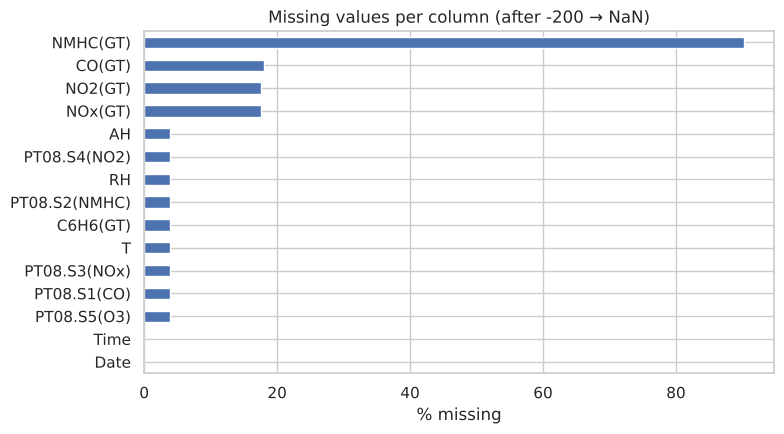

In [ ]:
df = df_raw.copy()
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]      # empty columns
df = df.dropna(how="all")                                   # empty rows
df = df.replace(-200, np.nan)                               # sentinel -> NaN
print("Rows after removing empty rows:", len(df))

miss = df.isna().mean().sort_values(ascending=False) * 100
print("\nMissing values (%):")
print(miss.round(2).to_string())

plt.figure(figsize=(8, 4.5))
miss.sort_values().plot.barh(color="#4C72B0")
plt.xlabel("% missing"); plt.title("Missing values per column (after -200 → NaN)")
plt.tight_layout(); plt.show()

In [ ]:
df = df.drop(columns=["NMHC(GT)"])                 # ~90 % missing
df = df.dropna(subset=["CO(GT)"]).reset_index(drop=True)   # target must be known
sensor_cols = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]
outage = df[sensor_cols].isna().all(axis=1)                 # sensor outage: no feature at all
print("Rows with CO reference but all sensors missing (dropped):", int(outage.sum()))
df = df.loc[~outage].reset_index(drop=True)
print("Rows kept for modelling:", len(df))

Rows with CO reference but all sensors missing (dropped): 330
Rows kept for modelling: 7344


### 1.3 Feature engineering and encoding of categorical features
`Date` and `Time` are strings. We parse them into a timestamp and derive **categorical** variables – *time of day* (Night / Morning / Afternoon / Evening) and *day type* (Weekday / Weekend) – which are **one-hot encoded** (with `drop_first=True` to avoid the dummy-variable trap).

In [ ]:
ts = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
df["Hour"] = ts.dt.hour
df["TimeOfDay"] = pd.cut(df["Hour"], bins=[-1, 5, 11, 17, 23],
                         labels=["Night", "Morning", "Afternoon", "Evening"])
df["DayType"] = np.where(ts.dt.dayofweek >= 5, "Weekend", "Weekday")

target = "CO(GT)"
# NOTE: to build a genuine low-cost *soft sensor* we keep only the cheap sensors + weather and
# exclude other reference analysers (C6H6, NOx, NO2 'GT' columns), which would make the task trivial.
numeric_features = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)",
                    "PT08.S5(O3)", "T", "RH", "AH"]

cat_features = ["TimeOfDay", "DayType"]
X = pd.concat([df[numeric_features],
               pd.get_dummies(df[cat_features], drop_first=True, dtype=float)], axis=1)
y = df[target].values
print("Feature matrix:", X.shape)
print("Columns:", list(X.columns))
X.head()

Feature matrix: (7344, 12)
Columns: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening', 'DayType_Weekend']


,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,TimeOfDay_Morning,TimeOfDay_Afternoon,TimeOfDay_Evening,DayType_Weekend
0,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,0.0,0.0,1.0,0.0
1,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,0.0,0.0,1.0,0.0
2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,0.0,0.0,1.0,0.0
3,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,0.0,0.0,1.0,0.0
4,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,0.0,0.0,1.0,0.0


### 1.4 Exploratory data analysis

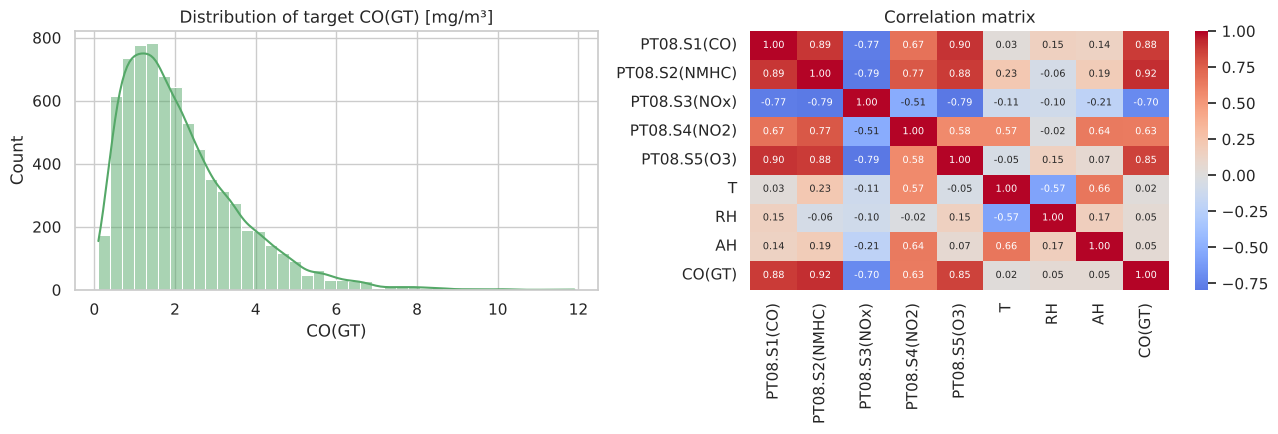

count    7344.000
mean        2.130
std         1.436
min         0.100
25%         1.100
50%         1.800
75%         2.800
max        11.900
Name: CO(GT), dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[target], bins=40, kde=True, ax=ax[0], color="#55A868")
ax[0].set_title("Distribution of target CO(GT) [mg/m³]")
corr = pd.concat([X[numeric_features], df[target]], axis=1).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1], annot_kws={"size": 7})
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

print(df[target].describe().round(3))

---
# 2. Train / Test Split, Imputation and Scaling
The data are split **80 % / 20 %**. Imputation and standardisation statistics are learned on the training set only and applied to the test set.

In [ ]:
X_tr_df, X_te_df, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

imputer = SimpleImputer(strategy="median").fit(X_tr_df)
X_tr_i = pd.DataFrame(imputer.transform(X_tr_df), columns=X.columns)
X_te_i = pd.DataFrame(imputer.transform(X_te_df), columns=X.columns)

scaler = StandardScaler().fit(X_tr_i)
X_tr = pd.DataFrame(scaler.transform(X_tr_i), columns=X.columns)
X_te = pd.DataFrame(scaler.transform(X_te_i), columns=X.columns)

print(f"Train: {X_tr.shape}, Test: {X_te.shape}")
print("Remaining NaNs  train/test:", X_tr.isna().sum().sum(), X_te.isna().sum().sum())

# ---- helpers shared by all models --------------------------------------------------------
results = {}
preds = {}

def evaluate(name, p_tr, p_te, fit_time, n_params):
    mse_tr, mse_te = mean_squared_error(y_tr, p_tr), mean_squared_error(y_te, p_te)
    results[name] = {
        "Train MSE": mse_tr, "Test MSE": mse_te,
        "Train RMSE": np.sqrt(mse_tr), "Test RMSE": np.sqrt(mse_te),
        "Train R2": r2_score(y_tr, p_tr), "Test R2": r2_score(y_te, p_te),
        "Test MAE": mean_absolute_error(y_te, p_te),
        "Fit/Predict time (s)": fit_time, "# parameters": n_params,
    }
    preds[name] = p_te
    r = results[name]
    print(f"{name:32s} | Test MSE={r['Test MSE']:.4f}  RMSE={r['Test RMSE']:.4f}  R2={r['Test R2']:.4f}"
          f"  (Train R2={r['Train R2']:.4f})  time={fit_time:.3f}s")

Train: (5875, 12), Test: (1469, 12)
Remaining NaNs  train/test: 0 0


---
# 3. Model Implementation & Training
## 3.1 Simple Linear Regression
One predictor is used. We pick the sensor with the **highest absolute correlation with the target on the training set**.

PT08.S2(NMHC)    0.915
PT08.S1(CO)      0.879
PT08.S5(O3)      0.853
PT08.S3(NOx)     0.699
PT08.S4(NO2)     0.630
AH               0.052
RH               0.051
T                0.021

Best single predictor: PT08.S2(NMHC)
Simple Linear                    | Test MSE=0.3042  RMSE=0.5515  R2=0.8441  (Train R2=0.8368)  time=0.002s

Equation (standardised x): CO = 2.136 + 1.323 × PT08.S2(NMHC)


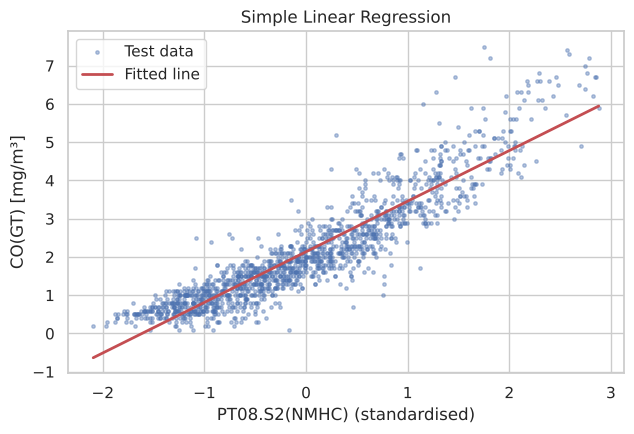

In [ ]:
num_corr = X_tr[numeric_features].corrwith(pd.Series(y_tr)).abs().sort_values(ascending=False)
print(num_corr.round(3).to_string())
best_feat = num_corr.index[0]
print("\nBest single predictor:", best_feat)

t0 = time.perf_counter()
slr = LinearRegression().fit(X_tr[[best_feat]], y_tr)
ft = time.perf_counter() - t0
evaluate("Simple Linear", slr.predict(X_tr[[best_feat]]), slr.predict(X_te[[best_feat]]), ft, 2)
print(f"\nEquation (standardised x): CO = {slr.intercept_:.3f} + {slr.coef_[0]:.3f} × {best_feat}")

plt.figure(figsize=(6.5, 4.5))
plt.scatter(X_te[best_feat], y_te, s=6, alpha=0.4, label="Test data")
xs = np.linspace(X_te[best_feat].min(), X_te[best_feat].max(), 100)
plt.plot(xs, slr.predict(pd.DataFrame({best_feat: xs})), "r", lw=2, label="Fitted line")
plt.xlabel(f"{best_feat} (standardised)"); plt.ylabel("CO(GT) [mg/m³]")
plt.title("Simple Linear Regression"); plt.legend(); plt.tight_layout(); plt.show()

## 3.2 Multiple (Multivariate) Linear Regression
All sensor, weather and encoded time features are used together.

Multiple Linear                  | Test MSE=0.1935  RMSE=0.4398  R2=0.9009  (Train R2=0.8891)  time=0.004s


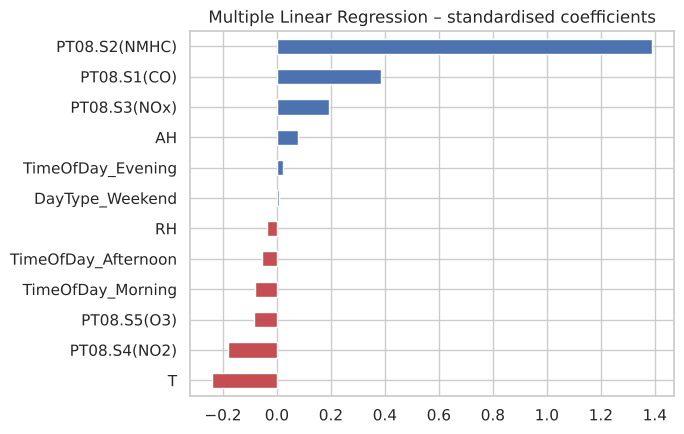

In [ ]:
t0 = time.perf_counter()
mlr = LinearRegression().fit(X_tr, y_tr)
ft = time.perf_counter() - t0
evaluate("Multiple Linear", mlr.predict(X_tr), mlr.predict(X_te), ft, X_tr.shape[1] + 1)

coef = pd.Series(mlr.coef_, index=X_tr.columns).sort_values()
plt.figure(figsize=(7, 4.5))
coef.plot.barh(color=np.where(coef > 0, "#4C72B0", "#C44E52"))
plt.title("Multiple Linear Regression – standardised coefficients"); plt.tight_layout(); plt.show()

## 3.3 Polynomial Regression (degree 2)
Two versions: **(a)** polynomial of the single best predictor (curve fitting), **(b)** multivariate degree-2 polynomial (squares + pairwise interactions) of all numeric features, with the one-hot features appended linearly.

Polynomial deg-2 (single)        | Test MSE=0.2505  RMSE=0.5005  R2=0.8717  (Train R2=0.8653)  time=0.002s
Polynomial deg-2 (multivariate)  | Test MSE=0.1567  RMSE=0.3959  R2=0.9197  (Train R2=0.9180)  time=0.015s
Polynomial feature count (multivariate): 48


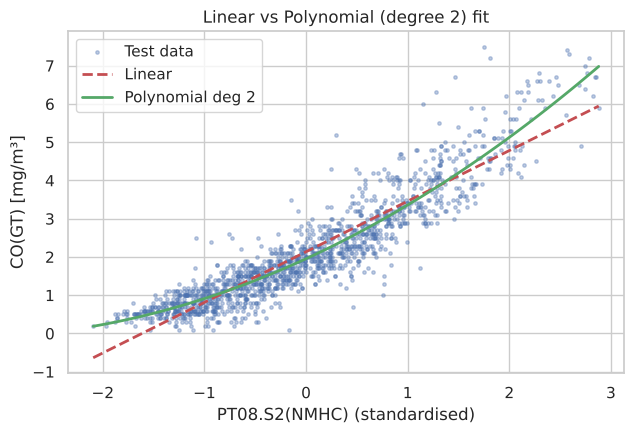

In [ ]:
# (a) single-feature polynomial
poly1 = PolynomialFeatures(degree=2, include_bias=False)
P_tr = poly1.fit_transform(X_tr[[best_feat]]); P_te = poly1.transform(X_te[[best_feat]])
t0 = time.perf_counter()
pr1 = LinearRegression().fit(P_tr, y_tr); ft = time.perf_counter() - t0
evaluate("Polynomial deg-2 (single)", pr1.predict(P_tr), pr1.predict(P_te), ft, P_tr.shape[1] + 1)

# (b) multivariate polynomial
dummy_cols = [c for c in X_tr.columns if c not in numeric_features]
polyM = PolynomialFeatures(degree=2, include_bias=False)
PM_tr = np.hstack([polyM.fit_transform(X_tr[numeric_features]), X_tr[dummy_cols].values])
PM_te = np.hstack([polyM.transform(X_te[numeric_features]), X_te[dummy_cols].values])
t0 = time.perf_counter()
prM = LinearRegression().fit(PM_tr, y_tr); ft = time.perf_counter() - t0
evaluate("Polynomial deg-2 (multivariate)", prM.predict(PM_tr), prM.predict(PM_te), ft, PM_tr.shape[1] + 1)
print("Polynomial feature count (multivariate):", PM_tr.shape[1])

plt.figure(figsize=(6.5, 4.5))
plt.scatter(X_te[best_feat], y_te, s=6, alpha=0.35, label="Test data")
plt.plot(xs, slr.predict(pd.DataFrame({best_feat: xs})), "r--", lw=2, label="Linear")
plt.plot(xs, pr1.predict(poly1.transform(pd.DataFrame({best_feat: xs}))), "g", lw=2, label="Polynomial deg 2")
plt.xlabel(f"{best_feat} (standardised)"); plt.ylabel("CO(GT) [mg/m³]")
plt.title("Linear vs Polynomial (degree 2) fit"); plt.legend(); plt.tight_layout(); plt.show()

## 3.4 Locally Weighted Linear Regression (LWLR)
LWLR is non-parametric: for each query point a separate weighted least-squares problem is solved, so nearby training points influence the prediction most.
The bandwidth $\tau$ is chosen on a **validation subset carved out of the training data** (never the test set).

In [ ]:
def lwlr_predict(Xb_train, y_train, Xq, tau, lam=1e-3):
    # Xb_train has a bias column; Xq are query rows (no bias column)
    d = Xb_train.shape[1]
    out = np.empty(len(Xq))
    for i, x in enumerate(Xq):
        diff = Xb_train[:, 1:] - x
        w = np.exp(-(diff ** 2).sum(1) / (2 * tau ** 2))
        A = Xb_train.T @ (w[:, None] * Xb_train) + lam * np.eye(d)
        theta = np.linalg.solve(A, Xb_train.T @ (w * y_train))
        out[i] = np.r_[1.0, x] @ theta
    return out

Xtr_np, Xte_np = X_tr.values, X_te.values
Xb_tr = np.c_[np.ones(len(Xtr_np)), Xtr_np]

# ---- choose tau using a validation split of the training set ----
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.permutation(len(Xtr_np))
val_idx, fit_idx = idx[:300], idx[300:]
Xb_fit, y_fit = Xb_tr[fit_idx], y_tr[fit_idx]
tau_grid = [0.4, 0.6, 0.8, 1, 1.5, 2, 3, 5]
val_rmse = {}
for tau in tau_grid:
    p = lwlr_predict(Xb_fit, y_fit, Xtr_np[val_idx], tau)
    val_rmse[tau] = np.sqrt(mean_squared_error(y_tr[val_idx], p))
    print(f"tau={tau:<3} validation RMSE = {val_rmse[tau]:.4f}")
best_tau = min(val_rmse, key=val_rmse.get)
print("\nBest tau:", best_tau)

tau=0.4 validation RMSE = 0.3923
tau=0.6 validation RMSE = 0.3825


tau=0.8 validation RMSE = 0.3830
tau=1   validation RMSE = 0.3985


tau=1.5 validation RMSE = 0.4308
tau=2   validation RMSE = 0.4485


tau=3   validation RMSE = 0.4742
tau=5   validation RMSE = 0.5042

Best tau: 0.6


In [ ]:
t0 = time.perf_counter()
lw_te = lwlr_predict(Xb_tr, y_tr, Xte_np, best_tau)
ft = time.perf_counter() - t0
# train score estimated on a 1000-point random subset of the training data (LWLR has no explicit fit step)
sub = rng.choice(len(Xtr_np), 1000, replace=False)
lw_tr_sub = lwlr_predict(Xb_tr, y_tr, Xtr_np[sub], best_tau)

# evaluate() expects full-length train predictions -> use the subset for train metrics only
mse_tr = mean_squared_error(y_tr[sub], lw_tr_sub)
mse_te = mean_squared_error(y_te, lw_te)
results["LWLR"] = {"Train MSE": mse_tr, "Test MSE": mse_te, "Train RMSE": np.sqrt(mse_tr), "Test RMSE": np.sqrt(mse_te),
                   "Train R2": r2_score(y_tr[sub], lw_tr_sub), "Test R2": r2_score(y_te, lw_te),
                   "Test MAE": mean_absolute_error(y_te, lw_te), "Fit/Predict time (s)": ft,
                   "# parameters": np.nan}   # non-parametric: keeps the whole training set
preds["LWLR"] = lw_te
r = results["LWLR"]
print(f"LWLR (tau={best_tau}) | Test MSE={r['Test MSE']:.4f}  RMSE={r['Test RMSE']:.4f}  R2={r['Test R2']:.4f}  time={ft:.2f}s")

LWLR (tau=0.6) | Test MSE=0.1188  RMSE=0.3447  R2=0.9391  time=0.51s


## 3.5 Gradient Descent for Linear Regression (from scratch)
We implement **batch**, **mini-batch** and **stochastic** gradient descent with the update rule $\theta\leftarrow\theta-\alpha\,\frac1m X^T(X\theta-y)$, then
1. study the effect of the **learning rate** $\alpha$,
2. compare convergence of the three variants,
3. verify the result against the closed-form Normal-equation solution.

In [ ]:
Xb_train = np.c_[np.ones(len(X_tr)), X_tr.values]
Xb_test = np.c_[np.ones(len(X_te)), X_te.values]

def gradient_descent(Xb, y, lr=0.1, epochs=300, batch_size=None, seed=RANDOM_STATE):
    # batch_size=None -> full batch; 1 -> stochastic; k -> mini-batch. Returns theta and cost history per epoch.
    rng = np.random.default_rng(seed)
    m, n = Xb.shape
    theta = np.zeros(n)
    history = []
    bs = m if batch_size is None else batch_size
    for _ in range(epochs):
        order = rng.permutation(m) if bs < m else np.arange(m)
        for s in range(0, m, bs):
            b = order[s:s + bs]
            grad = Xb[b].T @ (Xb[b] @ theta - y[b]) / len(b)
            theta -= lr * grad
        history.append(((Xb @ theta - y) ** 2).mean() / 2)        # J(theta)
    return theta, np.array(history)

# closed-form reference
theta_ne = np.linalg.solve(Xb_train.T @ Xb_train, Xb_train.T @ y_tr)
J_opt = ((Xb_train @ theta_ne - y_tr) ** 2).mean() / 2
print(f"Optimal cost from Normal equation: J* = {J_opt:.5f}")

Optimal cost from Normal equation: J* = 0.11599


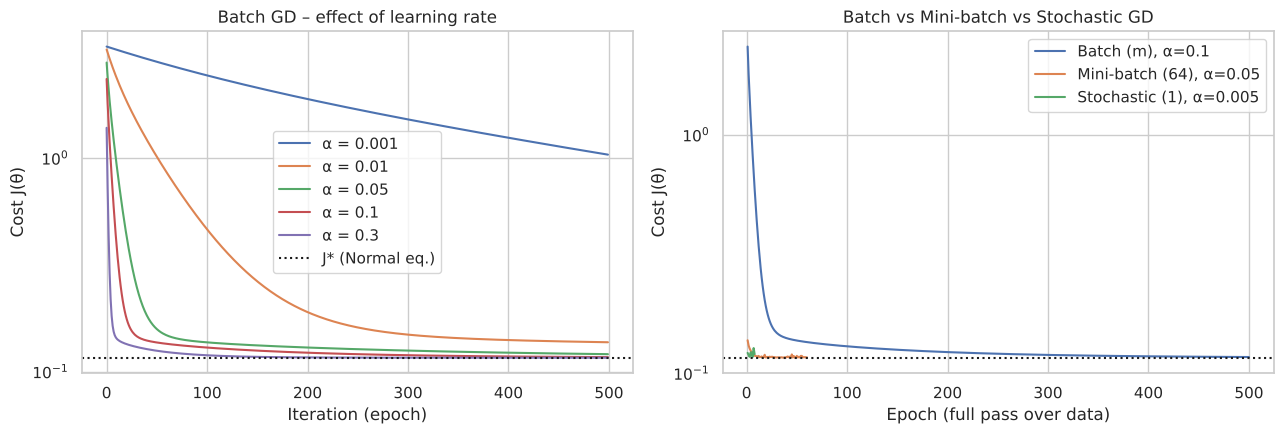

Variant               final J   ||θ-θ_NE||   time(s)
Batch (m)             0.11678      0.21541     0.147
Mini-batch (64)       0.11648      0.01903     0.061
Stochastic (1)        0.12005      0.07962     0.275


In [ ]:
# ---- (1) effect of the learning rate (batch GD) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for lr in [0.001, 0.01, 0.05, 0.1, 0.3]:
    _, h = gradient_descent(Xb_train, y_tr, lr=lr, epochs=500)
    ax[0].plot(h, label=f"α = {lr}")
ax[0].axhline(J_opt, color="k", ls=":", label="J* (Normal eq.)")
ax[0].set_yscale("log"); ax[0].set_xlabel("Iteration (epoch)"); ax[0].set_ylabel("Cost J(θ)")
ax[0].set_title("Batch GD – effect of learning rate"); ax[0].legend()

# ---- (2) batch vs mini-batch vs stochastic ----
variants = {"Batch (m)": None, "Mini-batch (64)": 64, "Stochastic (1)": 1}
gd_runs = {}
for name, bs in variants.items():
    lr = 0.1 if bs is None else (0.05 if bs == 64 else 0.005)
    ep = 500 if bs is None else (60 if bs == 64 else 8)
    t0 = time.perf_counter()
    th, h = gradient_descent(Xb_train, y_tr, lr=lr, epochs=ep, batch_size=bs)
    gd_runs[name] = (th, h, time.perf_counter() - t0)
    ax[1].plot(np.arange(1, len(h) + 1), h, label=f"{name}, α={lr}")
ax[1].axhline(J_opt, color="k", ls=":")
ax[1].set_yscale("log"); ax[1].set_xlabel("Epoch (full pass over data)"); ax[1].set_ylabel("Cost J(θ)")
ax[1].set_title("Batch vs Mini-batch vs Stochastic GD"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"{'Variant':18s} {'final J':>10s} {'||θ-θ_NE||':>12s} {'time(s)':>9s}")
for name, (th, h, t) in gd_runs.items():
    print(f"{name:18s} {h[-1]:10.5f} {np.linalg.norm(th - theta_ne):12.5f} {t:9.3f}")

Gradient Descent (batch)         | Test MSE=0.1935  RMSE=0.4398  R2=0.9009  (Train R2=0.8891)  time=0.752s

max |θ_GD − θ_NormalEq| = 2.6206104662751528e-05


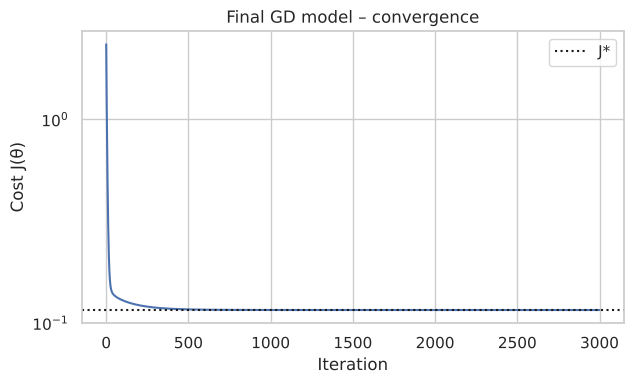

In [ ]:
# ---- final GD model: batch GD, alpha = 0.1, 3000 iterations ----
t0 = time.perf_counter()
theta_gd, hist = gradient_descent(Xb_train, y_tr, lr=0.1, epochs=3000)
ft = time.perf_counter() - t0
evaluate("Gradient Descent (batch)", Xb_train @ theta_gd, Xb_test @ theta_gd, ft, len(theta_gd))

print("\nmax |θ_GD − θ_NormalEq| =", np.abs(theta_gd - theta_ne).max())
plt.figure(figsize=(6.5, 4))
plt.plot(hist); plt.axhline(J_opt, color="k", ls=":", label="J*"); plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("Cost J(θ)"); plt.title("Final GD model – convergence"); plt.legend()
plt.tight_layout(); plt.show()

## 3.6 Ridge, Lasso and Elastic Net Regression
The regularisation strength $\alpha$ (and the L1 ratio for Elastic Net) is selected by **5-fold cross-validation on the training set**.

Ridge                            | Test MSE=0.1935  RMSE=0.4399  R2=0.9009  (Train R2=0.8890)  time=0.779s
   best alpha = 3.5565
Lasso                            | Test MSE=0.1935  RMSE=0.4398  R2=0.9009  (Train R2=0.8891)  time=0.035s
   best alpha = 0.0001 | non-zero coefficients: 12 of 12


Elastic Net                      | Test MSE=0.1935  RMSE=0.4398  R2=0.9009  (Train R2=0.8891)  time=0.162s
   best alpha = 0.00041 | best l1_ratio = 0.1 | non-zero coefficients: 12 of 12


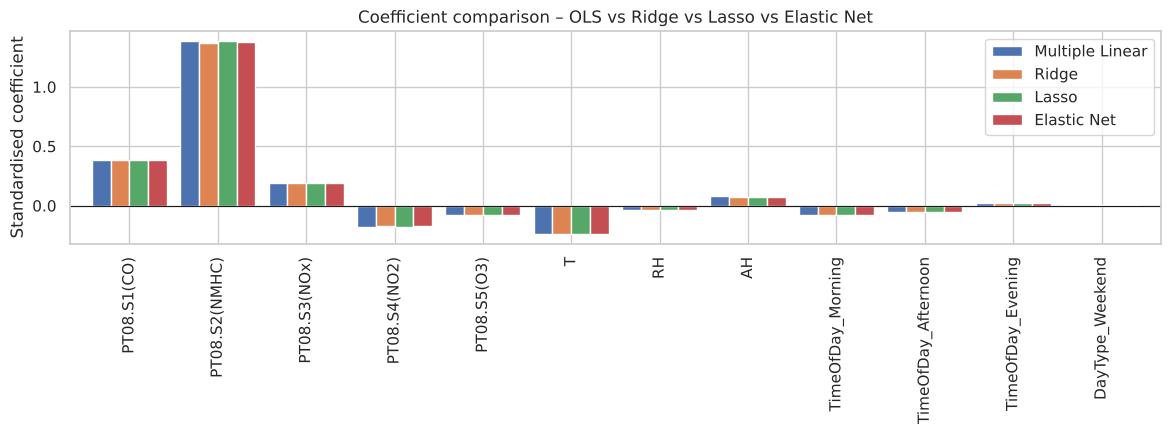

,Multiple Linear,Ridge,Lasso,Elastic Net
PT08.S1(CO),0.3870,0.3850,0.3850,0.3850
PT08.S2(NMHC),1.3896,1.3740,1.3859,1.3785
PT08.S3(NOx),0.1939,0.1903,0.1928,0.1913
PT08.S4(NO2),-0.1829,-0.1733,-0.1800,-0.1758
PT08.S5(O3),-0.0831,-0.0761,-0.0807,-0.0778
T,-0.2394,-0.2378,-0.2366,-0.2372
RH,-0.0350,-0.0342,-0.0328,-0.0336
AH,0.0778,0.0725,0.0742,0.0731
TimeOfDay_Morning,-0.0817,-0.0806,-0.0812,-0.0809
TimeOfDay_Afternoon,-0.0542,-0.0519,-0.0534,-0.0525


In [ ]:
t0 = time.perf_counter()
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_tr, y_tr); ft = time.perf_counter() - t0
evaluate("Ridge", ridge.predict(X_tr), ridge.predict(X_te), ft, X_tr.shape[1] + 1)
print("   best alpha =", round(ridge.alpha_, 4))

t0 = time.perf_counter()
lasso = LassoCV(alphas=np.logspace(-4, 0, 50), cv=5, random_state=RANDOM_STATE, max_iter=20000).fit(X_tr, y_tr); ft = time.perf_counter() - t0
evaluate("Lasso", lasso.predict(X_tr), lasso.predict(X_te), ft, int((lasso.coef_ != 0).sum()) + 1)
print("   best alpha =", round(lasso.alpha_, 5), "| non-zero coefficients:", int((lasso.coef_ != 0).sum()), "of", len(lasso.coef_))

t0 = time.perf_counter()
enet = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0], alphas=np.logspace(-4, 0, 40), cv=5,
                    random_state=RANDOM_STATE, max_iter=20000).fit(X_tr, y_tr); ft = time.perf_counter() - t0
evaluate("Elastic Net", enet.predict(X_tr), enet.predict(X_te), ft, int((enet.coef_ != 0).sum()) + 1)
print("   best alpha =", round(enet.alpha_, 5), "| best l1_ratio =", enet.l1_ratio_,
      "| non-zero coefficients:", int((enet.coef_ != 0).sum()), "of", len(enet.coef_))

coef_df = pd.DataFrame({"Multiple Linear": mlr.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_, "Elastic Net": enet.coef_},
                       index=X_tr.columns)
coef_df.plot.bar(figsize=(12, 4.5), width=0.85)
plt.title("Coefficient comparison – OLS vs Ridge vs Lasso vs Elastic Net"); plt.ylabel("Standardised coefficient")
plt.axhline(0, color="k", lw=0.8); plt.tight_layout(); plt.show()
coef_df.round(4)

---
# 4. Comparative Analysis

In [ ]:
res = pd.DataFrame(results).T
order = ["Simple Linear", "Multiple Linear", "Polynomial deg-2 (single)", "Polynomial deg-2 (multivariate)",
         "LWLR", "Gradient Descent (batch)", "Ridge", "Lasso", "Elastic Net"]
res = res.loc[order]
display_cols = ["Train R2", "Test R2", "Test MSE", "Test RMSE", "Test MAE", "Fit/Predict time (s)", "# parameters"]
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
table = res[display_cols].sort_values("Test R2", ascending=False).copy()
table["# parameters"] = table["# parameters"].astype("Int64")   # LWLR is non-parametric -> <NA>
table

,Train R2,Test R2,Test MSE,Test RMSE,Test MAE,Fit/Predict time (s),# parameters
LWLR,0.9733,0.9391,0.1188,0.3447,0.2225,0.5132,<NA>
Polynomial deg-2 (multivariate),0.9180,0.9197,0.1567,0.3959,0.2614,0.0150,49
Multiple Linear,0.8891,0.9009,0.1935,0.4398,0.3123,0.0043,13
Gradient Descent (batch),0.8891,0.9009,0.1935,0.4398,0.3123,0.7525,13
Lasso,0.8891,0.9009,0.1935,0.4398,0.3123,0.0351,13
Elastic Net,0.8891,0.9009,0.1935,0.4398,0.3124,0.1617,13
Ridge,0.8890,0.9009,0.1935,0.4399,0.3124,0.7791,13
Polynomial deg-2 (single),0.8653,0.8717,0.2505,0.5005,0.3634,0.0021,3
Simple Linear,0.8368,0.8441,0.3042,0.5515,0.4180,0.0022,2


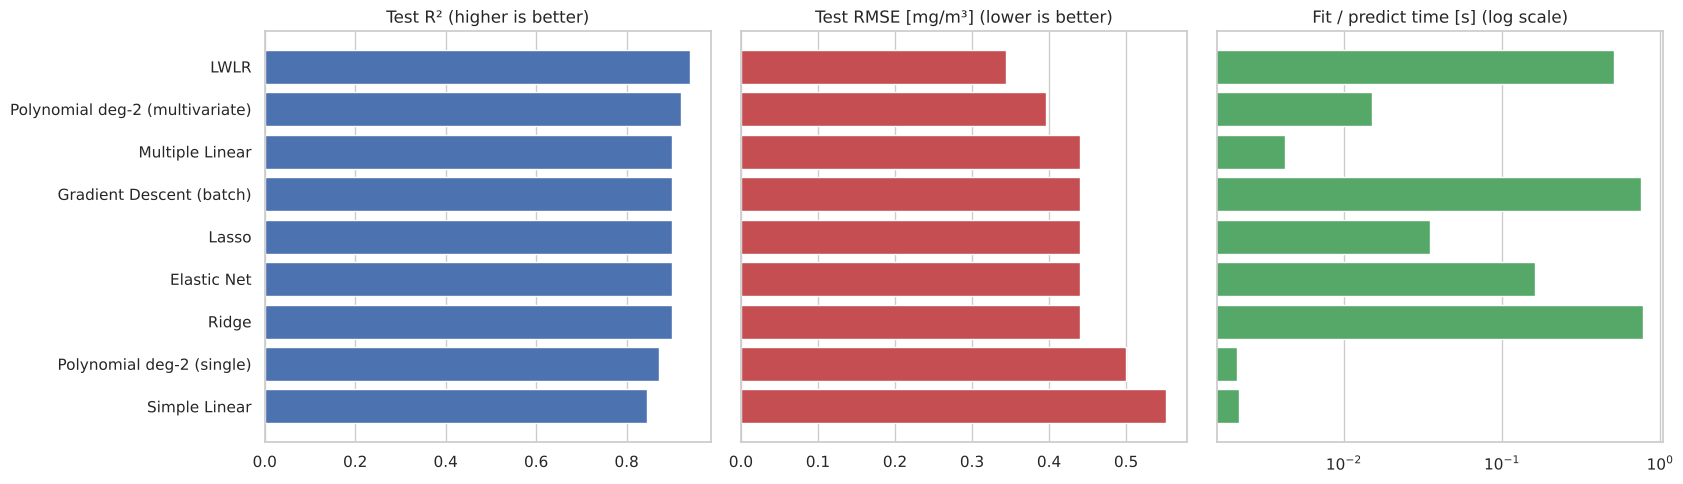

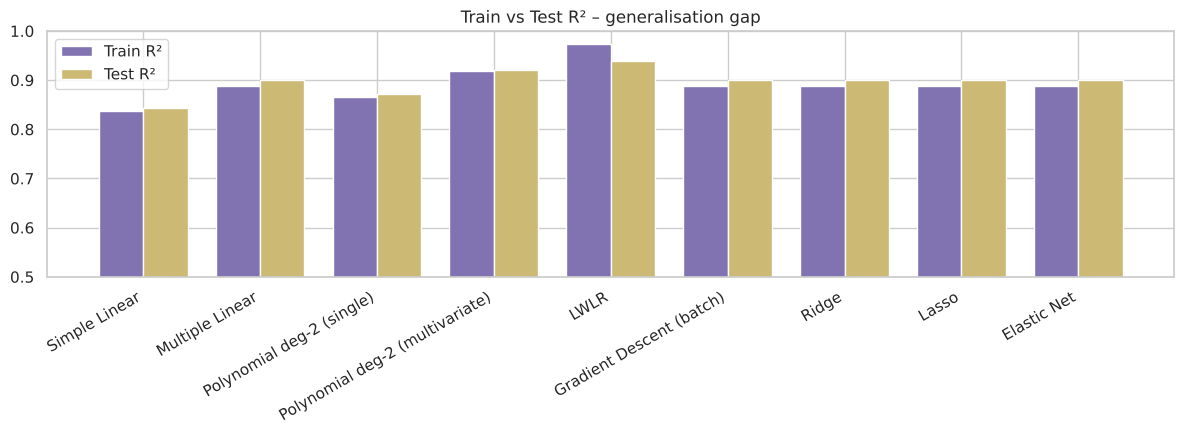

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
srt = res.sort_values("Test R2")
ax[0].barh(srt.index, srt["Test R2"], color="#4C72B0");   ax[0].set_title("Test R² (higher is better)")
ax[1].barh(srt.index, srt["Test RMSE"], color="#C44E52"); ax[1].set_title("Test RMSE [mg/m³] (lower is better)")
ax[1].set_yticklabels([])
ax[2].barh(srt.index, srt["Fit/Predict time (s)"], color="#55A868"); ax[2].set_xscale("log")
ax[2].set_title("Fit / predict time [s] (log scale)"); ax[2].set_yticklabels([])
for a in ax: a.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

# train vs test R2 (over-/under-fitting check)
x = np.arange(len(res)); w = 0.38
plt.figure(figsize=(12, 4.5))
plt.bar(x - w/2, res["Train R2"], w, label="Train R²", color="#8172B2")
plt.bar(x + w/2, res["Test R2"], w, label="Test R²", color="#CCB974")
plt.xticks(x, res.index, rotation=30, ha="right"); plt.ylim(min(0.5, res[["Train R2","Test R2"]].values.min() - 0.02), 1)
plt.title("Train vs Test R² – generalisation gap"); plt.legend(); plt.tight_layout(); plt.show()

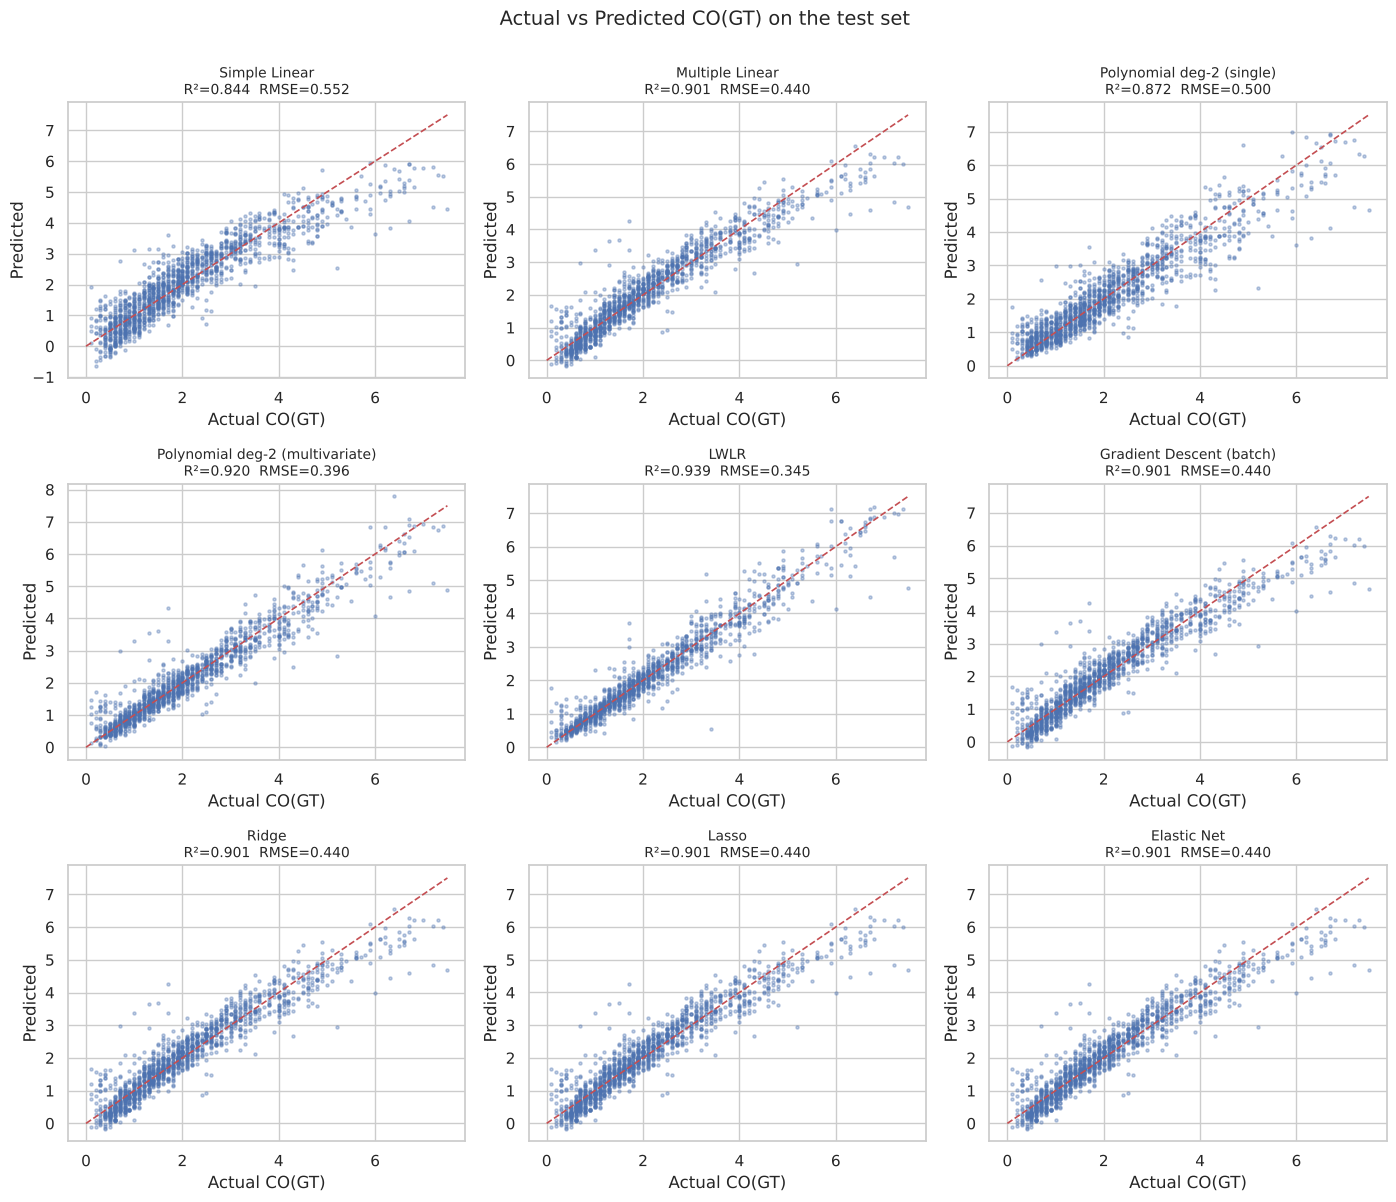

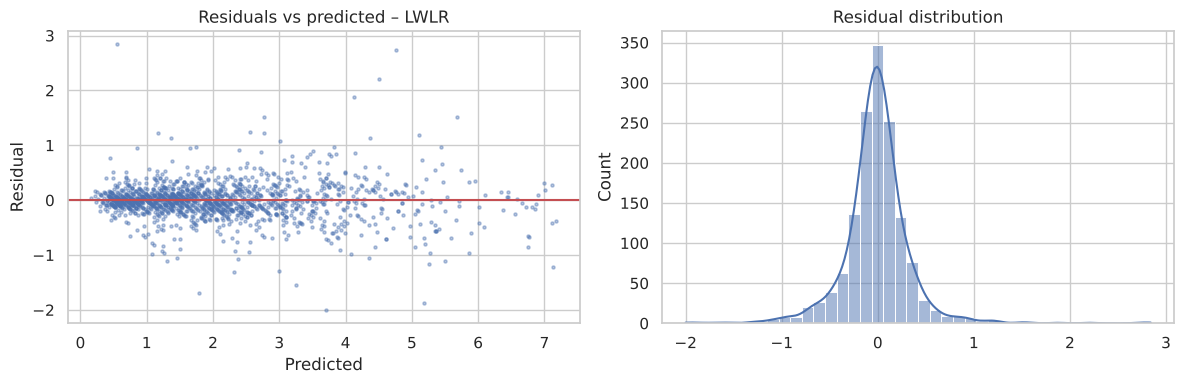

Best model on test R²: LWLR


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
lims = [0, max(y_te.max(), 1)]
for a, name in zip(axes.ravel(), order):
    a.scatter(y_te, preds[name], s=5, alpha=0.35)
    a.plot(lims, lims, "r--", lw=1.2)
    a.set_title(f"{name}\nR²={results[name]['Test R2']:.3f}  RMSE={results[name]['Test RMSE']:.3f}", fontsize=10)
    a.set_xlabel("Actual CO(GT)"); a.set_ylabel("Predicted")
plt.suptitle("Actual vs Predicted CO(GT) on the test set", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

# residuals of the best model
best_name = res["Test R2"].idxmax()
resid = y_te - preds[best_name]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(preds[best_name], resid, s=5, alpha=0.4); ax[0].axhline(0, color="r")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title(f"Residuals vs predicted – {best_name}")
sns.histplot(resid, bins=40, kde=True, ax=ax[1], color="#4C72B0"); ax[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()
print("Best model on test R²:", best_name)

---
# [8] Results Analysis

**Setup:** 7 344 usable hourly records (after removing 114 empty rows, 1 683 rows with no CO reference value and 330 rows where every sensor was offline) → 5 875 training / 1 469 test samples. Target CO(GT): mean 2.13 mg/m³, std 1.44 mg/m³. Features: 5 metal-oxide sensors, T, RH, AH and 4 one-hot encoded time features.

### 8.1 Performance summary (test set, `random_state = 42`)

| Rank | Model | Test R² | Test MSE | Test RMSE | Test MAE | Fit/predict time |
|:--:|---|:--:|:--:|:--:|:--:|:--:|
| 1 | LWLR (τ = 0.6) | **0.9391** | 0.1188 | **0.3447** | 0.223 | ≈ 0.5 s (all of it at prediction time) |
| 2 | Polynomial deg-2 (multivariate) | 0.9197 | 0.1567 | 0.3959 | 0.261 | 0.012 s |
| 3 | Multiple Linear | 0.9009 | 0.1935 | 0.4398 | 0.312 | 0.004 s |
| 3 | Gradient Descent (batch, 3000 its) | 0.9009 | 0.1935 | 0.4398 | 0.312 | ≈ 0.9 s |
| 3 | Lasso (α ≈ 1·10⁻⁴) | 0.9009 | 0.1935 | 0.4398 | 0.312 | 0.05 s (incl. 5-fold CV) |
| 3 | Elastic Net (l1_ratio = 0.1) | 0.9009 | 0.1935 | 0.4398 | 0.312 | 0.2 s (incl. CV) |
| 3 | Ridge (α ≈ 3.6) | 0.9009 | 0.1935 | 0.4399 | 0.312 | 0.9 s (incl. 5-fold CV) |
| 8 | Polynomial deg-2 (single feature) | 0.8717 | 0.2505 | 0.5005 | 0.363 | 0.001 s |
| 9 | Simple Linear (PT08.S2) | 0.8441 | 0.3042 | 0.5515 | 0.418 | 0.002 s |

*(Re-running the notebook regenerates the tables and figures above; timings vary with hardware.)*

### 8.2 Key observations

1. **Simple → Multiple regression (R² 0.844 → 0.901).** Adding the other sensors, weather and time features lowers RMSE from 0.552 to 0.440 mg/m³ (≈ 20 %). The dominant predictor is PT08.S2 (standardised coefficient ≈ 1.39), followed by PT08.S1 (≈ 0.39), temperature (≈ –0.24), PT08.S3 (≈ 0.19) and PT08.S4 (≈ –0.18). The time-of-day/weekend dummies have small coefficients (|θ| < 0.09) – the sensors already capture most of the daily cycle.
2. **Non-linearity exists.** Degree-2 polynomials improve on their linear counterparts: single-feature 0.844 → 0.872 and multivariate 0.901 → 0.920 (RMSE 0.440 → 0.396). Train R² (0.918) and test R² (0.920) are practically equal, so the 48 polynomial terms do **not** over-fit here – the large data size (5 875 rows) supports them.
3. **LWLR is the most accurate model (R² 0.939, RMSE 0.345)** because it adapts the fit locally to each operating regime of the sensors. The price is (a) it must store the whole training set, (b) every prediction solves a weighted least-squares problem (≈ 0.5 s for 1 469 queries versus microseconds for a linear model), and (c) a larger train–test gap (train R² ≈ 0.97 on a training subset vs 0.94 on test, and the train points are part of their own neighbourhood), i.e. higher variance. The validation RMSE was flat for τ = 0.4 – 0.8 and rose steadily for larger τ (τ → ∞ reduces LWLR to ordinary linear regression).
4. **Gradient Descent reproduces the Normal-equation solution.** With standardised features, α = 0.1 and 3 000 iterations, the largest coefficient difference from the closed form is ≈ 3·10⁻⁵, and test metrics are identical (R² 0.9009). Learning-rate study: α = 0.001 and 0.01 are still far from the optimum after 500 iterations, while α = 0.05 – 0.3 converge quickly on standardised data. Convergence of the last digits is slow because the PT08 sensors are strongly inter-correlated (an elongated cost surface). Mini-batch GD (batch size 64) reached a cost of 0.1165 (optimum J* = 0.1160) in only 60 epochs, whereas batch GD needed 500 epochs to reach 0.1168; pure SGD with a constant step size hovers around the optimum (J ≈ 0.120) – a decaying learning rate would be needed for exact convergence.
5. **Ridge, Lasso and Elastic Net match OLS (R² 0.9009).** With only 12 features, ≈ 5 900 training samples and moderate noise, the variance of OLS is already low, so cross-validation picks weak penalties (Ridge α ≈ 3.6, Lasso α ≈ 1·10⁻⁴, Elastic Net α ≈ 4·10⁻⁴ with l1_ratio = 0.1); none of the 12 coefficients is shrunk to zero and the coefficients are almost identical to OLS. Regularisation therefore gives *no accuracy gain* on this dataset, but it does not hurt, and it would protect against multicollinearity and over-fitting if more (e.g. polynomial or lagged) features were added.
6. **Residuals.** The actual-vs-predicted plots show that errors spread out for high CO concentrations and that the linear models under-predict the largest peaks (a single global line cannot follow the saturating sensor response); LWLR and the polynomial model follow the diagonal more closely.
7. **Data-quality lesson.** 330 hours had a CO reference value but *no* sensor data at all. Median-imputing them produced one identical prediction for all of them (in an earlier trial this showed up as a horizontal streak of points in the actual-vs-predicted plots) and inflated every error; dropping them improved all models (e.g. multiple-linear R² rose from ≈ 0.82 to 0.90). Handling missing data deserves as much care as model choice.

### 8.3 Strengths, weaknesses, interpretability, efficiency and complexity

| Model | Strengths | Weaknesses | Interpretability | Computational efficiency | Model complexity |
|---|---|---|---|---|---|
| Simple Linear | Very simple, fast, easy to plot | Highest error (R² 0.84); ignores other information | ★★★★★ | Excellent | 2 parameters |
| Multiple Linear | Strong, stable baseline; closed form; coefficients readable | Cannot model curvature; sensitive to collinearity | ★★★★☆ | Excellent (≈ ms) | 13 parameters |
| Polynomial (deg 2) | Captures curvature/interactions; still convex & closed form | Features grow as O(d²); risk of over-fitting, extrapolates badly | ★★★☆☆ | Very good | 49 parameters (multivariate) |
| LWLR | Best accuracy; flexible local fit, no global form assumed | Memory-based, slow prediction O(n·d²) per query; needs τ tuning; higher variance; no single equation | ★★☆☆☆ | Poor for prediction/large n | Non-parametric (stores all data) |
| Gradient Descent | Scales to very large data and online learning; same optimum as OLS | Needs scaling, learning-rate and iteration tuning; slower than closed form for small d | ★★★★☆ (same model as OLS) | Good (mini-batch best trade-off) | 13 parameters |
| Ridge | Stabilises coefficients under collinearity | Needs α tuning; keeps all features | ★★★★☆ | Very good | 13 parameters |
| Lasso | Embedded feature selection, sparse models | Unstable among correlated features | ★★★★★ (sparse) | Very good | ≤ 13 parameters |
| Elastic Net | Combines L1 + L2; robust for correlated groups | Two hyper-parameters | ★★★★☆ | Very good | ≤ 13 parameters |

---
# [9] Conclusion

- A complete regression workflow was applied to a real-world air-quality problem: cleaning the `-200` sentinel values, discarding the 90 %-missing NMHC column and the sensor-outage rows, engineering and one-hot-encoding time features, imputing and scaling without leakage, and evaluating nine models with MSE, RMSE and R².
- **All models explain 84 – 94 % of the variance of CO(GT)** from low-cost sensors alone, confirming that metal-oxide sensors plus weather data can act as a **virtual CO sensor**. The best-performing model is **LWLR (R² = 0.939, RMSE = 0.345 mg/m³)**, followed by the **multivariate degree-2 polynomial (R² = 0.920, RMSE = 0.396 mg/m³)** and the linear family (R² = 0.901, RMSE = 0.440 mg/m³).
- **Gradient descent** converges to the Normal-equation solution when features are standardised and α is chosen well; mini-batch GD is the most efficient variant.
- **Regularisation** (Ridge/Lasso/Elastic Net) did not change accuracy because the problem has few features and many samples; its value here is robustness rather than accuracy.


---
**Learning outcome achieved:** data pre-processing, implementation of simple, multiple, polynomial, locally weighted, gradient-descent and regularised regression models, and comparative performance evaluation using MSE, RMSE and R².